In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Single random seed used everywhere
SEED = 42


In [2]:
df = pd.read_parquet("../data/processed/metropt3_cleaned.parquet")
df.head()

,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_electric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
timestamp,,,,,,,,,,,,,,,
2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


### K-Means Clustering

In [3]:
df['row_count'] = 1

agg_funcs = {
    'TP2': ['mean','std','min','max'],
    'TP3': ['mean','std','min','max'],
    'H1': ['mean','std','min','max'],
    'DV_pressure': ['mean','std','min','max'],
    'Reservoirs': ['mean','std','min','max'],
    'Oil_temperature': ['mean','std','min','max'],
    'Motor_current': ['mean','std','min','max'],
    'COMP': 'mean',
    'DV_electric': 'mean',
    'Towers': 'mean',
    'MPG': 'mean',
    'LPS': 'mean',
    'Pressure_switch': 'mean',
    'Oil_level': 'mean',
    'Caudal_impulses': 'mean',
    'row_count': ['sum']
}

windows = df.resample('5min').agg(agg_funcs)
windows.columns = ['_'.join(c) if isinstance(c, tuple) else c for c in windows.columns]

windows = windows.dropna(subset=['Motor_current_mean'])
windows = windows.reset_index()


In [4]:
windows.shape

(50782, 38)

In [5]:
windows.head()

,timestamp,TP2_mean,TP2_std,TP2_min,TP2_max,TP3_mean,TP3_std,TP3_min,TP3_max,H1_mean,...,Motor_current_max,COMP_mean,DV_electric_mean,Towers_mean,MPG_mean,LPS_mean,Pressure_switch_mean,Oil_level_mean,Caudal_impulses_mean,row_count_sum
0,2020-02-01 00:00:00,-0.012645,0.000950,-0.014,-0.012,9.203742,0.093492,9.050,9.358,9.187548,...,0.0425,1.000000,0.000000,1.000000,1.000000,0.0,1.0,1.0,1.0,31
1,2020-02-01 00:05:00,-0.013400,0.000932,-0.014,-0.012,8.898667,0.085163,8.760,9.040,8.883933,...,0.0425,1.000000,0.000000,1.000000,1.000000,0.0,1.0,1.0,1.0,30
2,2020-02-01 00:10:00,-0.013800,0.000610,-0.014,-0.012,8.616667,0.080064,8.488,8.750,8.602800,...,0.0400,1.000000,0.000000,1.000000,1.000000,0.0,1.0,1.0,1.0,30
3,2020-02-01 00:15:00,-0.013871,0.000885,-0.016,-0.012,8.348452,0.077550,8.222,8.478,8.334774,...,0.0400,1.000000,0.000000,1.000000,1.000000,0.0,1.0,1.0,1.0,31
4,2020-02-01 00:20:00,3.153867,4.571355,-0.026,10.314,8.544267,0.676387,8.068,10.098,5.470800,...,6.2825,0.633333,0.366667,0.833333,0.633333,0.0,1.0,1.0,1.0,30


In [6]:
windows.columns

Index(['timestamp', 'TP2_mean', 'TP2_std', 'TP2_min', 'TP2_max', 'TP3_mean',
       'TP3_std', 'TP3_min', 'TP3_max', 'H1_mean', 'H1_std', 'H1_min',
       'H1_max', 'DV_pressure_mean', 'DV_pressure_std', 'DV_pressure_min',
       'DV_pressure_max', 'Reservoirs_mean', 'Reservoirs_std',
       'Reservoirs_min', 'Reservoirs_max', 'Oil_temperature_mean',
       'Oil_temperature_std', 'Oil_temperature_min', 'Oil_temperature_max',
       'Motor_current_mean', 'Motor_current_std', 'Motor_current_min',
       'Motor_current_max', 'COMP_mean', 'DV_electric_mean', 'Towers_mean',
       'MPG_mean', 'LPS_mean', 'Pressure_switch_mean', 'Oil_level_mean',
       'Caudal_impulses_mean', 'row_count_sum'],
      dtype='object')

In [7]:
sample_interval = df.index.to_series().diff().median() # verify actual sampling interval before assuming 1Hz
print(sample_interval)


0 days 00:00:10


<Axes: >

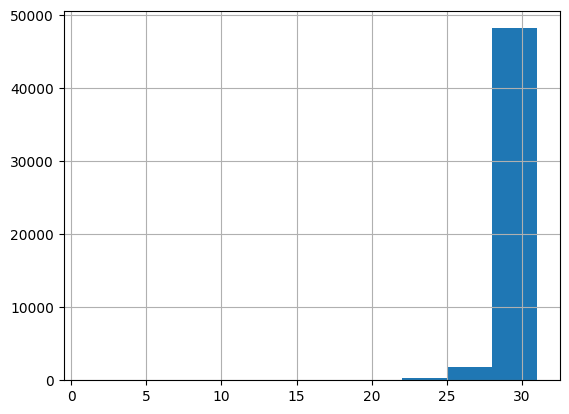

In [8]:
windows['row_count_sum'].hist()

In [9]:
failure_periods = [
    ("2020-04-18 00:00", "2020-04-18 23:59"),
    ("2020-05-29 23:30", "2020-05-30 06:00"),
    ("2020-06-05 10:00", "2020-06-07 14:30"),
    ("2020-07-15 14:30", "2020-07-15 19:00"),
]
failure_periods = [(pd.to_datetime(s), pd.to_datetime(e)) for s, e in failure_periods]

# Label failure if the window overlaps a failure period (start < period end and window end > period start).
WINDOW_MIN = 5
INCOMPLETE_THRESHOLD = 0.5  # keep a window only if it holds at least 50% of expected rows

interval_seconds = df.index.to_series().diff().median().total_seconds()
expected_count = (WINDOW_MIN * 60) / interval_seconds

windows['failure'] = 0
windows['window_start'] = windows['timestamp']
windows['window_end'] = windows['timestamp'] + pd.Timedelta(minutes=WINDOW_MIN)

for start, end in failure_periods:
    mask = (windows['window_start'] < end) & (windows['window_end'] > start)
    windows.loc[mask, 'failure'] = 1

windows['incomplete_window'] = windows['row_count_sum'] < (expected_count * INCOMPLETE_THRESHOLD)
print(windows['incomplete_window'].value_counts())

dropped_failure_overlap = windows.loc[windows['incomplete_window'], 'failure'].sum()
print(f"Windows being dropped that overlap a documented failure: {dropped_failure_overlap}")

windows = windows[~windows['incomplete_window']].copy()
print(windows.shape)


incomplete_window
False    50513
True       269
Name: count, dtype: int64
Windows being dropped that overlap a documented failure: 2
(50513, 42)


In [10]:
windows.head()

,timestamp,TP2_mean,TP2_std,TP2_min,TP2_max,TP3_mean,TP3_std,TP3_min,TP3_max,H1_mean,...,MPG_mean,LPS_mean,Pressure_switch_mean,Oil_level_mean,Caudal_impulses_mean,row_count_sum,failure,window_start,window_end,incomplete_window
0,2020-02-01 00:00:00,-0.012645,0.000950,-0.014,-0.012,9.203742,0.093492,9.050,9.358,9.187548,...,1.000000,0.0,1.0,1.0,1.0,31,0,2020-02-01 00:00:00,2020-02-01 00:05:00,False
1,2020-02-01 00:05:00,-0.013400,0.000932,-0.014,-0.012,8.898667,0.085163,8.760,9.040,8.883933,...,1.000000,0.0,1.0,1.0,1.0,30,0,2020-02-01 00:05:00,2020-02-01 00:10:00,False
2,2020-02-01 00:10:00,-0.013800,0.000610,-0.014,-0.012,8.616667,0.080064,8.488,8.750,8.602800,...,1.000000,0.0,1.0,1.0,1.0,30,0,2020-02-01 00:10:00,2020-02-01 00:15:00,False
3,2020-02-01 00:15:00,-0.013871,0.000885,-0.016,-0.012,8.348452,0.077550,8.222,8.478,8.334774,...,1.000000,0.0,1.0,1.0,1.0,31,0,2020-02-01 00:15:00,2020-02-01 00:20:00,False
4,2020-02-01 00:20:00,3.153867,4.571355,-0.026,10.314,8.544267,0.676387,8.068,10.098,5.470800,...,0.633333,0.0,1.0,1.0,1.0,30,0,2020-02-01 00:20:00,2020-02-01 00:25:00,False


In [11]:
windows = windows.drop(columns='incomplete_window')

In [12]:
windows.head()

,timestamp,TP2_mean,TP2_std,TP2_min,TP2_max,TP3_mean,TP3_std,TP3_min,TP3_max,H1_mean,...,Towers_mean,MPG_mean,LPS_mean,Pressure_switch_mean,Oil_level_mean,Caudal_impulses_mean,row_count_sum,failure,window_start,window_end
0,2020-02-01 00:00:00,-0.012645,0.000950,-0.014,-0.012,9.203742,0.093492,9.050,9.358,9.187548,...,1.000000,1.000000,0.0,1.0,1.0,1.0,31,0,2020-02-01 00:00:00,2020-02-01 00:05:00
1,2020-02-01 00:05:00,-0.013400,0.000932,-0.014,-0.012,8.898667,0.085163,8.760,9.040,8.883933,...,1.000000,1.000000,0.0,1.0,1.0,1.0,30,0,2020-02-01 00:05:00,2020-02-01 00:10:00
2,2020-02-01 00:10:00,-0.013800,0.000610,-0.014,-0.012,8.616667,0.080064,8.488,8.750,8.602800,...,1.000000,1.000000,0.0,1.0,1.0,1.0,30,0,2020-02-01 00:10:00,2020-02-01 00:15:00
3,2020-02-01 00:15:00,-0.013871,0.000885,-0.016,-0.012,8.348452,0.077550,8.222,8.478,8.334774,...,1.000000,1.000000,0.0,1.0,1.0,1.0,31,0,2020-02-01 00:15:00,2020-02-01 00:20:00
4,2020-02-01 00:20:00,3.153867,4.571355,-0.026,10.314,8.544267,0.676387,8.068,10.098,5.470800,...,0.833333,0.633333,0.0,1.0,1.0,1.0,30,0,2020-02-01 00:20:00,2020-02-01 00:25:00


In [13]:
windows.shape

(50513, 41)

In [14]:
windows.isna().sum()

timestamp               0
TP2_mean                0
TP2_std                 0
TP2_min                 0
TP2_max                 0
TP3_mean                0
TP3_std                 0
TP3_min                 0
TP3_max                 0
H1_mean                 0
H1_std                  0
H1_min                  0
H1_max                  0
DV_pressure_mean        0
DV_pressure_std         0
DV_pressure_min         0
DV_pressure_max         0
Reservoirs_mean         0
Reservoirs_std          0
Reservoirs_min          0
Reservoirs_max          0
Oil_temperature_mean    0
Oil_temperature_std     0
Oil_temperature_min     0
Oil_temperature_max     0
Motor_current_mean      0
Motor_current_std       0
Motor_current_min       0
Motor_current_max       0
COMP_mean               0
DV_electric_mean        0
Towers_mean             0
MPG_mean                0
LPS_mean                0
Pressure_switch_mean    0
Oil_level_mean          0
Caudal_impulses_mean    0
row_count_sum           0
failure     

In [15]:
from sklearn.preprocessing import StandardScaler

# 36 features: 4 stats x 7 continuous sensors + 8 digital means.
CONTINUOUS = ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current']
DIGITAL = ['COMP', 'DV_electric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']

feature_cols = (
    [f'{c}_{stat}' for c in CONTINUOUS for stat in ['mean', 'std', 'min', 'max']]
    + [f'{c}_mean' for c in DIGITAL]
)
assert len(feature_cols) == 36, f'expected 36 features, got {len(feature_cols)}'

X = windows[feature_cols].copy()

# Drop single-reading windows (NaN std) on purpose before scaling.
nan_std_cols = [f'{c}_std' for c in CONTINUOUS]
before = len(X)
X = X.replace([np.inf, -np.inf], np.nan)
kept_index = X.dropna(subset=nan_std_cols).index
X = X.loc[kept_index]
after = len(X)
print(f'Dropped {before - after} windows with NaN std before scaling')

assert not X.isna().any().any(), 'NaN values remain in features'
assert np.isfinite(X.values).all(), 'infinite values remain in features'

# Keep windows aligned with X.
windows = windows.loc[kept_index].reset_index(drop=True)
X = X.reset_index(drop=True)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


Dropped 0 windows with NaN std before scaling


C:\Users\Aryan\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Aryan\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\Aryan\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Aryan\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

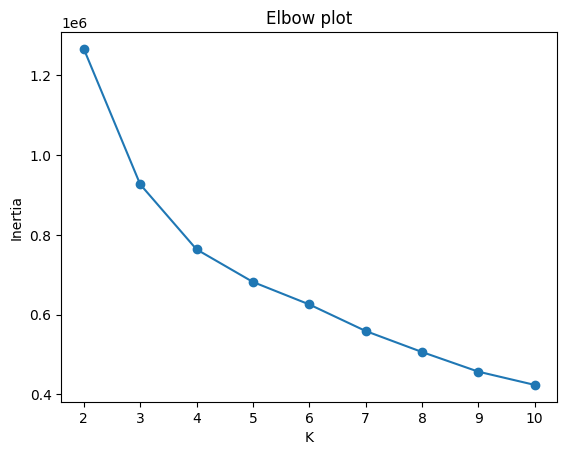

In [16]:
from sklearn.cluster import KMeans
inertias = []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
plt.plot(K_range, inertias, marker='o')
plt.xlabel('K'); plt.ylabel('Inertia'); plt.title('Elbow plot')
plt.show()


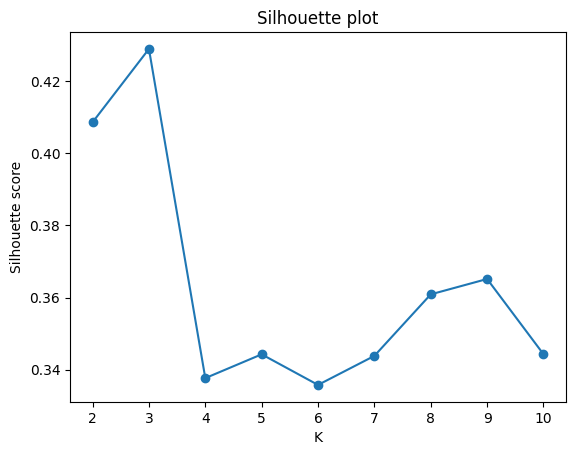

In [17]:
from sklearn.metrics import silhouette_score
sil_scores = []
for k in K_range:
 km = KMeans(n_clusters=k, random_state=42, n_init=20)
 labels = km.fit_predict(X_scaled)
 sil_scores.append(silhouette_score(X_scaled, labels, sample_size=10000, random_state=42))
plt.plot(K_range, sil_scores, marker='o')
plt.xlabel('K'); plt.ylabel('Silhouette score'); plt.title('Silhouette plot')
plt.show()

In [18]:
decision_table = pd.DataFrame({'K': list(K_range), 'Inertia': inertias, 'Silhouette': sil_scores})
decision_table

,K,Inertia,Silhouette
0,2,1.266274e+06,0.408605
1,3,9.267051e+05,0.428946
2,4,7.636289e+05,0.337641
3,5,6.819644e+05,0.344244
4,6,6.255865e+05,0.335756
5,7,5.589793e+05,0.343812
6,8,5.063332e+05,0.360876
7,9,4.570267e+05,0.365138
8,10,4.238040e+05,0.344277


### Final K-Means model

In [19]:
FINAL_K = 3
kmeans = KMeans(n_clusters=FINAL_K, random_state=SEED, n_init=20)
windows['cluster'] = kmeans.fit_predict(X_scaled)
windows['cluster'].value_counts().sort_index()


cluster
0     3056
1    34097
2    13360
Name: count, dtype: int64

In [20]:
profile = windows.groupby('cluster')[feature_cols].mean()

# Name clusters from their profile (not the 0/1/2 IDs): highest current = high load, lowest pressure = idle, rest = cycling.
motor_mean = profile['Motor_current_mean']
pressure_mean = profile['DV_pressure_mean']

high_load_cluster = int(motor_mean.idxmax())
remaining = [c for c in profile.index if c != high_load_cluster]
idle_cluster = int(profile.loc[remaining, 'DV_pressure_mean'].idxmin())
cycling_cluster = [c for c in profile.index if c not in (high_load_cluster, idle_cluster)][0]

cluster_name = {
    high_load_cluster: 'Sustained high load',
    idle_cluster: 'Idle',
    cycling_cluster: 'Start/stop cycling',
}
windows['cluster_name'] = windows['cluster'].map(cluster_name)

# Assert every cluster is named.
assert windows['cluster_name'].notna().all(), 'every cluster must have a name'
assert set(cluster_name.values()) == {'Sustained high load', 'Idle', 'Start/stop cycling'}

profile['cluster_name'] = profile.index.map(cluster_name)
print(profile.T)


cluster                                 0          1                   2
TP2_mean                         8.096335   0.024726             3.30458
TP2_std                           0.48809   0.114061             4.32178
TP2_min                          6.853717  -0.014657           -0.018024
TP2_max                          8.441274   0.421588           10.333335
TP3_mean                         8.329573   8.959087            9.189223
TP3_std                          0.055329   0.131589            0.529163
TP3_min                          8.237611   8.748544            8.391126
TP3_max                          8.424035   9.184382           10.028905
H1_mean                         -0.009144   8.901311             5.84043
H1_std                           0.002575   0.253161            4.213402
H1_min                          -0.011056    8.29655            -0.01684
H1_max                           0.001357   9.165595            9.752283
DV_pressure_mean                 1.118516  -0.02016

In [21]:
counts = windows['cluster_name'].value_counts()
pct = (counts / counts.sum() * 100).round(1)
print(pct)


cluster_name
Idle                   67.5
Start/stop cycling     26.4
Sustained high load     6.0
Name: count, dtype: float64


cluster numbers are arbitrary, they don't mean anything on their own until profiled above

### PCA visualization

In [22]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=42)
pcs = pca.fit_transform(X_scaled)
windows['PC1'], windows['PC2'] = pcs[:,0], pcs[:,1]
print(pca.explained_variance_ratio_)

[0.35643888 0.21196756]


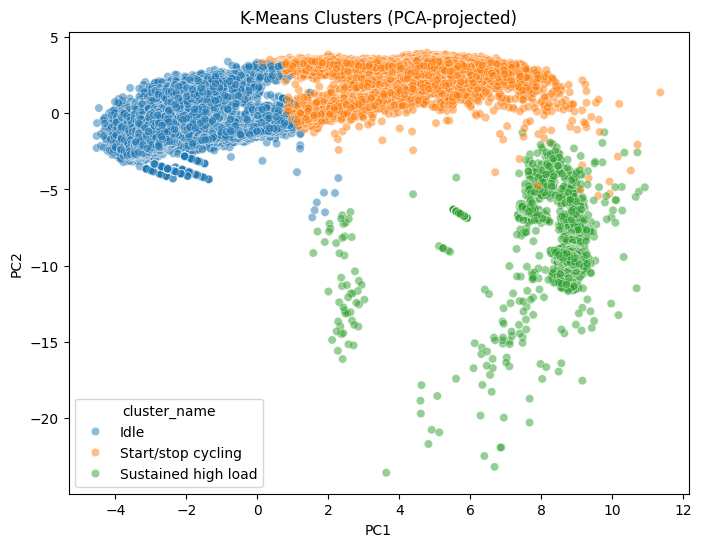

In [23]:
plt.figure(figsize=(8,6))
sns.scatterplot(x='PC1', y='PC2', hue='cluster_name', data=windows, palette='tab10', alpha=0.5)
plt.title('K-Means Clusters (PCA-projected)')
os.makedirs('../reports/figures', exist_ok=True)
plt.savefig("../reports/figures/pca_clusters_k3.png", dpi=120, bbox_inches='tight')
plt.show()


### Failure period association

In [24]:
windows['failure'].sum()

np.int64(992)

In [25]:
comparison = pd.crosstab(windows['cluster'], windows['failure'], normalize='columns') * 100
comparison

failure,0,1
cluster,,
0,4.182064,99.294355
1,68.843521,0.504032
2,26.974415,0.201613


### Export for Power BI

In [26]:
windows.shape

(50513, 45)

In [27]:
os.makedirs('../data/processed', exist_ok=True)
windows.to_csv("../data/processed/metropt3_windows_with_clusters.csv", index=False)
